# Ishigami benchmark: recovering an interaction without a marginal effect

The [Ishigami test function](https://salib.readthedocs.io/en/latest/user_guide/basics_with_interface.html) is a controlled regression problem with a known conditional mean. Three independent inputs are uniform on $[-\pi,\pi]$, and the response is

$$
Y = \sin(X_1) + 7\sin^2(X_2) + 0.1X_3^4\sin(X_1) + \varepsilon,
\qquad \varepsilon\sim N(0,0.5^2).
$$

The first two inputs have main effects. $X_3$ changes the amplitude of the $X_1$ effect but has no marginal mean effect: averaging over the symmetric $X_1$ distribution makes $E[\sin(X_1)]=0$. We add $X_4$ and $X_5$ as independent noise predictors. The target is the conditional mean $E[Y \mid X]$: the task is to identify the interaction from training data, fit a model that predicts it, and grade predictions against an independent sample and the exact generating mean. The formula and oracle mean are stated here for evaluation; neither enters screening or tuning.

:::{admonition} Study design
:class: dropdown

| | |
|---|---|
| **Response** | simulated continuous outcome, arbitrary response units |
| **Estimand** | conditional mean $E[Y\mid X]$ and its $X_1\times X_3$ interaction |
| **Sampling and split unit** | independent simulated rows; 800 train and 2,000 test |
| **Tuning** | five random training folds; common folds for both specifications |
| **Uncertainty** | 12 independent train/test draws in the extension; standard errors across draws |
| **Scope** | recovery under this generator and input distribution |
:::

## Training data

The frozen fixture is generated by `benches/bench_ishigami_recovery.py` from the sourced function and contains `y_signal`, the exact conditional mean. We remove that column before fitting or screening. The test sample has an independent seed and is held aside until the specifications have been chosen. Each row is one independent draw of the five inputs and the response, so the rows are exchangeable and the cross-validation folds split rows.

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")
fixture = pl.read_parquet(Path("../data/ishigami_reference.parquet"))
train_all = fixture.filter(pl.col("split") == "train").drop("split")
test_all = fixture.filter(pl.col("split") == "test").drop("split")
train = train_all.drop("y_signal")
test = test_all.drop("y_signal")
display(train.head(4))

x1,x2,x3,x4,x5,y
f64,f64,f64,f64,f64,f64
-2.017312,0.8791,-0.205659,-0.813669,-0.911581,4.480355
1.82538,2.545594,-2.02725,0.959975,-1.267301,5.408612
2.93401,2.637996,0.853701,1.587963,0.095213,2.700362
2.04766,-0.324335,-1.012771,-1.3955,-1.7195,1.75969


## Additive reference: `gamboost` and `cvrisk`

The first formula offers a smooth main effect for each candidate column. A P-spline can represent the sine and squared-sine curves, but an additive sum cannot change the `x1` curve with `x3`. We fit a long path at step length `nu=0.3` and use the same five training folds to choose `mstop`, the number of boosting updates, for both models below. The 20,000-step upper bound gives the risk curves room to turn.

In [2]:
base_formula = "y ~ " + " + ".join(
    f"bbs(x{i}, df=4, knots=8)" for i in range(1, 6)
)
folds = mb.cv_weights(train.height, type="kfold", B=5, seed=22026)
control = mb.boost_control(mstop=20000, nu=0.3)

base_path = mb.gamboost(base_formula, train, family=mb.Gaussian(), control=control)
base_cv = base_path.cvrisk(folds=folds)
base_fit = base_path[:base_cv.optimal_mstop]
print(f"Additive model: {base_fit.mstop} updates; "
      f"five-fold MSE {base_cv.aggregate[base_fit.mstop]:.3f}")

Additive model: 445 updates; five-fold MSE 4.075


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 5 learner(s): bbs(x5): 10.5 of 12 df after 6135 selections (one step: 3.44); bbs(x4): 10.3 of 12 df after 4734 selections (one step: 3.44); bbs(x1): 10.2 of 12 df after 4331 selections (one step: 3.44); bbs(x3): 9.83 of 12 df after 2382 selections (one step: 3.44); bbs(x2): 9.82 of 12 df after 2418 selections (one step: 3.44). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


The selected stopping point is {eval}`base_fit.mstop` updates. Its cross-validated mean squared error (MSE) is {eval}`f"{base_cv.aggregate[base_fit.mstop]:.2f}"` squared response units. This estimates prediction error for new rows from the same input distribution; it does not establish that every generating effect has been recovered.

## Residual interaction screen: `screen_interactions`

For a Gaussian model, `y - predict()` is the response-scale residual. `screen_interactions` uses half the training rows to estimate a binned surface for each pair and scores how much residual MSE it removes on the other half. This is a nomination step on training data; the later shared-fold comparison decides whether to retain its top pair.

In [3]:
residual = train["y"].to_numpy() - np.asarray(base_fit.predict())
leads = mb.screen_interactions(train, residual, response="y", seed=32026)
lead_rows = pl.DataFrame([
    {"pair": f"{item.left} × {item.right}", "removed": item.removed}
    for item in leads[:5]
])
table(lead_rows, title="Residual pair screen on the training data",
      subtitle="Held-half residual MSE removed, squared response units; higher is better",
      stub="pair", stubhead="Pair", labels={"removed": "MSE removed"},
      better={"removed": "max"},
      notes=["Each pair is binned on one half of the 800 training rows and scored on the other half; no test or oracle values enter."])

GT(_tbl_data=shape: (5, 2)
┌─────────┬───────────┐
│ pair    ┆ removed   │
│ ---     ┆ ---       │
│ str     ┆ f64       │
╞═════════╪═══════════╡
│ x1 × x3 ┆ 1.236786  │
│ x4 × x5 ┆ -0.024526 │
│ x1 × x2 ┆ -0.05224  │
│ x3 × x4 ┆ -0.090779 │
│ x2 × x4 ┆ -0.137708 │
└─────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10ee5fe30>, _boxhead=Boxhead([ColInfo(var='pair', type=<ColInfoTypeEnum.stub: 2>, column_label='pair', column_align='left', column_width=None), ColInfo(var='removed', type=<ColInfoTypeEnum.default: 1>, column_label='MSE removed', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d9d3b00>, _spanners=Spanners([]), _heading=Heading(title='Residual pair screen on the training data', subtitle='Held-half residual MSE removed, squared response units; higher is better', preheader=None), _stubhead='Pair', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fe54560>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd754c0>, _source_notes=['Each pair is binned on one half of the 800 training rows and scored on the other half; no test or oracle values enter.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fd33f20>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10d9d3d10>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d9f43e0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInf

The first-ranked pair is {eval}`f"{leads[0].left} × {leads[0].right}"`. Its held-half residual MSE reduction is {eval}`f"{leads[0].removed:.2f}"` squared response units. This points to joint structure left by the additive fit. It does not by itself estimate a calibrated selection probability.

## Screened tensor: `bbs %X% bbs`

A tensor of two spline bases represents a smooth surface over the nominated pair. We keep the same main effects, fold assignments, learning rate and path limit, then tune the expanded model. The paired CV comparison uses the same folds; because both stopping points were chosen from those folds, its gap is descriptive.

In [4]:
pair_term = (f"bbs({leads[0].left}, df=4, knots=8) %X% "
             f"bbs({leads[0].right}, df=4, knots=8)")
pair_formula = base_formula + " + " + pair_term
pair_path = mb.gamboost(pair_formula, train, family=mb.Gaussian(),
                        control=control)
pair_cv = pair_path.cvrisk(folds=folds)
pair_fit = pair_path[:pair_cv.optimal_mstop]
comparison = base_cv.compare_to(pair_cv)

print(f"Screened model: {pair_fit.mstop} updates; "
      f"five-fold MSE {pair_cv.aggregate[pair_fit.mstop]:.3f}")
print(comparison.describe())

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 4 learner(s): bbs(x2): 9.96 of 12 df after 2925 selections (one step: 3.44); bbs(x1, df=4, knots=8) %X% bbs(x3, df=4, knots=8): 103 of 142 df after 16307 selections (one step: 12.2); bbs(x4): 8.21 of 12 df after 463 selections (one step: 3.44); bbs(x5): 7.71 of 12 df after 305 selections (one step: 3.44). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


Screened model: 2503 updates; five-fold MSE 0.309
5 paired folds, mstop 445 vs 2503
  mean risk difference: 3.76573 (favours the second)
  standard error: 0.594958 corrected, 0.396639 uncorrected
  No calibrated interval: the two models were compared at their own selected optima, so the interval would not cover the tuning bias. The comparison is descriptive.


The tensor model selects {eval}`pair_fit.mstop` updates. Its mean CV MSE is lower by {eval}`f"{comparison.mean_difference:.2f}"` squared response units (corrected descriptive standard error {eval}`f"{comparison.se_corrected:.2f}"`). Both curves turn before the 20,000-step limit in this draw. The fold comparison supports testing the pair on independent rows, while the same-fold tuning prevents a calibrated interval for the gap.

## Fitted terms and interaction shape

`selection_counts` reports how often each offered learner was updated. It distinguishes the tensor from either main effect. An update count describes the algorithm's path, not a term's population importance.

In [5]:
counts = pl.DataFrame(pair_fit.selection_counts(output="records"))
table(counts, title="Learners updated in the screened model",
      subtitle=f"{pair_fit.mstop} boosting updates; share is a fraction of updates",
      stub="learner", stubhead="Learner",
      labels={"column": "Input columns", "updates": "Updates", "share": "Share"},
      better={"updates": "max"}, formats={"share": 3},
      notes=["Zero-update learners remain in the table. Counts do not measure effect size or independent predictive gain."])

GT(_tbl_data=shape: (6, 4)
┌─────────────────────────────────┬────────┬─────────┬──────────┐
│ learner                         ┆ column ┆ updates ┆ share    │
│ ---                             ┆ ---    ┆ ---     ┆ ---      │
│ str                             ┆ str    ┆ i64     ┆ f64      │
╞═════════════════════════════════╪════════╪═════════╪══════════╡
│ bbs(x1, df=4, knots=8) %X% bbs… ┆ x1,x3  ┆ 1228    ┆ 0.490611 │
│ x2                              ┆ x2     ┆ 1140    ┆ 0.455453 │
│ x4                              ┆ x4     ┆ 101     ┆ 0.040352 │
│ x5                              ┆ x5     ┆ 34      ┆ 0.013584 │
│ x1                              ┆ x1     ┆ 0       ┆ 0.0      │
│ x3                              ┆ x3     ┆ 0       ┆ 0.0      │
└─────────────────────────────────┴────────┴─────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10fef6450>, _boxhead=Boxhead([ColInfo(var='learner', type=<ColInfoTypeEnum.stub: 2>, column_label='learner', column_align='left', column_width=None), ColInfo(var='column', type=<ColInfoTypeEnum.default: 1>, column_label='Input columns', column_align='left', column_width=None), ColInfo(var='updates', type=<ColInfoTypeEnum.default: 1>, column_label='Updates', column_align='right', column_width=None), ColInfo(var='share', type=<ColInfoTypeEnum.default: 1>, column_label='Share', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x115545310>, _spanners=Spanners([]), _heading=Heading(title='Learners updated in the screened model', subtitle='2503 boosting updates; share is a fraction of updates', preheader=None), _stubhead='Learner', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e5d4a70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fedbaa0>, _source_notes=['Zero-update learners remain in the table. Counts do not measure effect size or independent predictive gain.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fedbf50>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10fedbad0>, <great_tables._gt_data.FormatInfo object at 0x10d9d3d70>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1155459a0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A

The tensor receives many updates while the separate `x3` spline receives none. The two irrelevant columns can still receive updates at a finite stopping point; their true effects are checked against the generating function below. The chart holds `x2`, `x4` and `x5` at zero and varies `x1` at two `x3` values. Each curve is centered at `x1=0`, so it shows the response change with `x1` on each slice rather than the model offset.

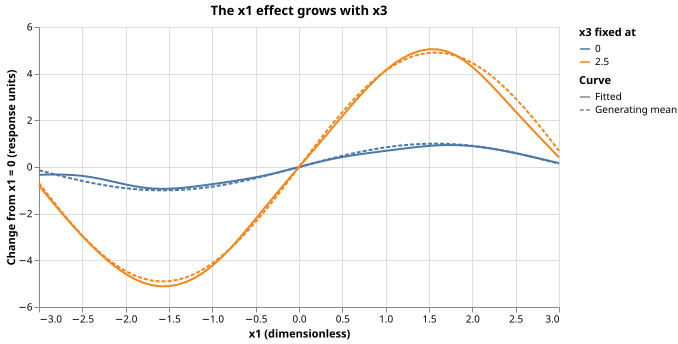

In [6]:
x1_grid = np.linspace(-3, 3, 61)
curve_rows = []
for x3_value in (0.0, 2.5):
    grid = pl.DataFrame({"x1": x1_grid, "x2": np.zeros(61),
                         "x3": np.full(61, x3_value),
                         "x4": np.zeros(61), "x5": np.zeros(61)})
    fitted = np.asarray(pair_fit.predict(grid))
    true = (1 + 0.1 * x3_value**4) * np.sin(x1_grid)
    for label, values in (("Fitted", fitted), ("Generating mean", true)):
        centered = values - values[30]
        curve_rows.extend({"x1": float(x), "change": float(v),
                           "x3": f"{x3_value:g}", "curve": label}
                          for x, v in zip(x1_grid, centered))
chart = alt.Chart(pl.DataFrame(curve_rows)).mark_line().encode(
    x=alt.X("x1:Q", title="x1 (dimensionless)"),
    y=alt.Y("change:Q", title="Change from x1 = 0 (response units)"),
    color=alt.Color("x3:N", title="x3 fixed at"),
    strokeDash=alt.StrokeDash("curve:N", title="Curve"),
).properties(title="The x1 effect grows with x3", width=520, height=280)
display(chart)

The fitted curves show the change in amplitude expected from the generating interaction. The plot evaluates two slices within the training support; it does not show the tensor's full surface or imply that the fitted equation has recovered the exact $x_3^4\sin(x_1)$ form.

## Independent prediction and generating mean

The test sample was not used to nominate the pair or choose either stopping point. Test MSE measures prediction of noisy observations. Signal MSE compares each prediction with the exact conditional mean, so it measures recovery of the generating regression surface. The oracle row uses that mean as a reference and was unavailable to fitting.

In [7]:
observed = test["y"].to_numpy()
signal = test_all["y_signal"].to_numpy()
rows = []
for method, prediction in (
    ("Additive model", np.asarray(base_fit.predict(test))),
    ("Screened tensor", np.asarray(pair_fit.predict(test))),
    ("Known mean (oracle)", signal),
):
    rows.append({"method": method,
                 "test_mse": float(np.mean((observed - prediction) ** 2)),
                 "signal_mse": float(np.mean((signal - prediction) ** 2))})
results = pl.DataFrame(rows)
table(results, title="Prediction and mean-function recovery on independent rows",
      subtitle="2,000 test rows; MSE in squared response units; lower is better",
      stub="method", stubhead="Specification",
      labels={"test_mse": "Test MSE", "signal_mse": "Signal MSE"},
      better={"test_mse": "min", "signal_mse": "min"},
      notes=["Test MSE scores noisy outcomes; signal MSE scores the known conditional mean. The oracle is a reference, not a fitted candidate."])

GT(_tbl_data=shape: (3, 3)
┌─────────────────────┬──────────┬────────────┐
│ method              ┆ test_mse ┆ signal_mse │
│ ---                 ┆ ---      ┆ ---        │
│ str                 ┆ f64      ┆ f64        │
╞═════════════════════╪══════════╪════════════╡
│ Additive model      ┆ 3.736205 ┆ 3.474403   │
│ Screened tensor     ┆ 0.311546 ┆ 0.046531   │
│ Known mean (oracle) ┆ 0.253713 ┆ 0.0        │
└─────────────────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10d9f4980>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='test_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Test MSE', column_align='right', column_width=None), ColInfo(var='signal_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Signal MSE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fe54470>, _spanners=Spanners([]), _heading=Heading(title='Prediction and mean-function recovery on independent rows', subtitle='2,000 test rows; MSE in squared response units; lower is better', preheader=None), _stubhead='Specification', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x115546930>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115214590>, _source_notes=['Test MSE scores noisy outcomes; signal MSE scores the known conditional mean. The oracle is a reference, not a fitted candidate.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x115214710>, _formats=[<great_tables._gt_data.FormatInfo object at 0x115544890>, <great_tables._gt_data.FormatInfo object at 0x115217b30>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x115214560>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=Option

The screened tensor's test MSE is {eval}`f"{results['test_mse'][1]:.2f}"`, compared with {eval}`f"{results['test_mse'][0]:.2f}"` for the additive model. Its signal MSE is {eval}`f"{results['signal_mse'][1]:.2f}"`; the oracle's test MSE of {eval}`f"{results['test_mse'][2]:.2f}"` is the realized observation-noise error on these rows. The improvement depends on offering a tensor after the residual screen. The algorithm discovers the pair, but the fitted spline surface approximates rather than identifies the symbolic generating formula.

## Extension: repeated training draws

The main analysis is one draw. `benches/bench_ishigami_recovery.py` repeats its selection, five-fold tuning and independent test scoring for 12 train/test seeds and writes `ishigami_recovery.json`. The book reads the committed result; the script contains the full reproducible experiment. Each draw regenerates the predictors and response, including the two irrelevant columns.

In [8]:
artifact = json.loads(Path("ishigami_recovery.json").read_text())
replicates = artifact["rows"]
summary_rows = []
for method, key in (("Additive model", "additive"),
                    ("Screened tensor", "screened_pair"),
                    ("Known mean (oracle)", "oracle")):
    test_scores = np.array([row[key]["test_mse"] for row in replicates])
    signal_scores = np.array([row[key]["signal_mse"] for row in replicates])
    summary_rows.append({"method": method, "test_mse": test_scores.mean(),
                         "test_se": test_scores.std(ddof=1) / np.sqrt(len(test_scores)),
                         "signal_mse": signal_scores.mean(),
                         "signal_se": signal_scores.std(ddof=1) / np.sqrt(len(signal_scores))})
summary = pl.DataFrame(summary_rows)
table(summary, title="Ishigami recovery across independent draws",
      subtitle="Mean MSE ± standard error across 12 draws; squared response units; lower is better",
      stub="method", stubhead="Specification",
      labels={"test_mse": "Mean", "test_se": "SE",
              "signal_mse": "Mean", "signal_se": "SE"},
      spanners={"Noisy test outcome": ["test_mse", "test_se"],
                "Generating mean": ["signal_mse", "signal_se"]},
      better={"test_mse": "min", "signal_mse": "min"},
      notes=["Each draw has 800 training and 2,000 independent test rows. SE is the standard deviation of the 12 draw-level MSEs divided by √12.",
             "Source and runner: SALib Ishigami function; benches/bench_ishigami_recovery.py; artifact ishigami_recovery.json."])

GT(_tbl_data=shape: (3, 5)
┌─────────────────────┬──────────┬──────────┬────────────┬───────────┐
│ method              ┆ test_mse ┆ test_se  ┆ signal_mse ┆ signal_se │
│ ---                 ┆ ---      ┆ ---      ┆ ---        ┆ ---       │
│ str                 ┆ f64      ┆ f64      ┆ f64        ┆ f64       │
╞═════════════════════╪══════════╪══════════╪════════════╪═══════════╡
│ Additive model      ┆ 3.77534  ┆ 0.064063 ┆ 3.505793   ┆ 0.065363  │
│ Screened tensor     ┆ 0.296657 ┆ 0.003824 ┆ 0.042627   ┆ 0.002533  │
│ Known mean (oracle) ┆ 0.250089 ┆ 0.001294 ┆ 0.0        ┆ 0.0       │
└─────────────────────┴──────────┴──────────┴────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x115545eb0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='test_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Mean', column_align='right', column_width=None), ColInfo(var='test_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='signal_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Mean', column_align='right', column_width=None), ColInfo(var='signal_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1152150d0>, _spanners=Spanners([SpannerInfo(spanner_id='Noisy test outcome', spanner_level=0, spanner_label='Noisy test outcome', spanner_units=None, spanner_pattern=None, vars=['test_mse', 'test_se'], built=None), SpannerInfo(spanner_id='Generating mean', spanner_level=0, spanner_label='Generating mean', spanner_units=None, spanner_pattern=None, vars=['signal_mse', 'signal_se'], built=None)]), _heading=Heading(title='Ishigami recovery across independent draws', subtitle='Mean MSE ± standard error across 12 draws; squared response units; lower is better', preheader=None), _stubhead='Specification', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x115215820>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x115215730>, _source_notes=['Each draw has 800 training and 2,000 independent test rows. SE is the standard deviation of the 12 draw-level MSEs divided by √12.', 'Source and runner: SALib Ishigami function; benches/bench_ishigami_recovery.py; artifact ishigami_recovery.json.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x115215520>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1152154f0>, <great_tables._gt_data.FormatInfo object at 0x115215610>, <great_tables._gt_data.FormatInfo object at 0x115215970>, <great_tables._gt_data.FormatInfo object at 0x115215a00>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x115215bb0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo

The screen ranks the true `x1 × x3` pair first in {eval}`sum(row["correct_pair"] for row in replicates)` of {eval}`len(replicates)` draws. Test MSE falls from {eval}`f"{summary['test_mse'][0]:.2f}"` to {eval}`f"{summary['test_mse'][1]:.2f}"` on average. No draw has its CV optimum at the 20,000-step limit. The irrelevant columns still receive an average of {eval}`f"{100 * np.mean([row['noise_update_share'] for row in replicates]):.1f}%"` of the screened fit's updates; selection counts alone would therefore overstate structural recovery. These draws come from one function and one input distribution. They do not show the same recovery rate under correlated inputs, weaker interactions or a different noise level.

## Extension: automatic specification

`autospec` combines learner selection, a preliminary search, held-out pair comparison and deselection. With the Gaussian family supplied by the caller, its report identifies that choice as declared. The formula below is an additional check of the automatic route; the main analysis above shows the separate decisions and their evidence.

In [9]:
recommendation = mb.autospec(
    train, "y", family=mb.Gaussian(), budget=120, mstop=300,
    seed=5, interactions="adopt", preexploration="native",
)
print(recommendation.formula)
print(next(line for line in recommendation.report().splitlines()
           if line.startswith("family:")))
print("Adopted interactions:", recommendation.evidence.get("adopted_interactions", ()))
print("Dropped terms:", recommendation.evidence.get("deselect").dropped)

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 277 is within 5% of the search cap 277; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 10000 is within 5% of the search cap 10000; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


y ~ bbs(x1, df=4.0) + bbs(x2, df=4.0) + bbs(x1, df=2.5, knots=5) %X% bbs(x3, df=2.5, knots=5)
family: Gaussian — supplied by the caller; no family comparison
Adopted interactions: ('bbs(x1, df=2.5, knots=5) %X% bbs(x3, df=2.5, knots=5)',)
Dropped terms: (('bbs(x3, df=4.0)', 0.0), ('bbs(x5, df=4.0)', 0.000216), ('bbs(x4, df=4.0)', 0.000282))


The automatic route also retains the `x1 × x3` tensor and removes the two noise columns. Its stopping search can reach its 10,000-step cap on this draw; that report is a lower bound on the best step count, not evidence that the risk has turned. Issue [#114](https://github.com/fcela/mboostrs/issues/114) tracks automatic extension of stopping searches. The family-report correction found while writing this case is tracked in [#172](https://github.com/fcela/mboostrs/issues/172).